# 01 - EDA and fixed split

**Owner:** Srivalli

**Part:** A (Data + EDA + fixed split)

Run `python -m src.dataset` once first, it makes `data/splits.csv`. Colours and histograms use the TRAIN images only, so the test set stays untouched.

In [1]:
import hashlib
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # the notebook runs in notebooks/, our code is one folder up

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.dataset import augment, check_split, get_loader
from src.utils import DATA_DIR, FIGURES_DIR, SPLITS_CSV

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(SPLITS_CSV)
train = df[df["split"] == "train"]
class_names = sorted(df["class_name"].unique())
print(len(df), "images,", len(class_names), "classes")

27000 images, 10 classes


## 1. Leakage check

This must print OK before anything else: the sizes are right, every class keeps its share, and no file is in two splits.

In [2]:
counts = check_split(df)
counts[["train", "val", "test"]]

Leakage check: OK
  split sizes: {'train': 18900, 'val': 4050, 'test': 4050}
  no file appears in two splits; every class keeps its share in every split


split,train,val,test
class_name,,,
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2100,450,450
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375


The check above compares file names. Two files with different names could still hold the same picture, so we also compare the bytes of every file (an MD5 fingerprint).

In [3]:
# Same fingerprint = exactly the same file content.
df["md5"] = [hashlib.md5((DATA_DIR / p).read_bytes()).hexdigest() for p in df["path"]]

splits_per_copy = df.groupby("md5")["split"].nunique()
same_content_across_splits = int((splits_per_copy > 1).sum())
print("identical pictures found in more than one split:", same_content_across_splits)
print("Content check:", "OK" if same_content_across_splits == 0 else "NOT OK, look at these files")

identical pictures found in more than one split: 0
Content check: OK


**What I see:** the sizes are exactly 18,900 / 4,050 / 4,050 and each class keeps its 70/15/15 share. No file name is in two splits, and no two files with identical bytes are in different splits, so there is no direct leakage. This does not rule out neighbouring patches of the same area landing in different splits (see the report's limitations section).

## 2. Class counts

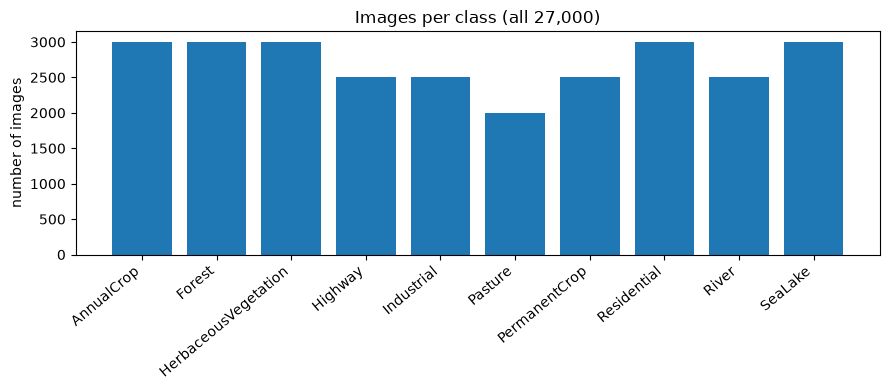

class_name
AnnualCrop              3000
Forest                  3000
HerbaceousVegetation    3000
Highway                 2500
Industrial              2500
Pasture                 2000
PermanentCrop           2500
Residential             3000
River                   2500
SeaLake                 3000


In [4]:
class_counts = df["class_name"].value_counts().reindex(class_names)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(class_names, class_counts)
ax.set_ylabel("number of images")
ax.set_title("Images per class (all 27,000)")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_class_counts.png", dpi=120)
plt.show()
print(class_counts.to_string())

**What I see:** the classes are not exactly equal. Five classes have 3,000 images, four have 2,500 and Pasture has the fewest with 2,000. This is a mild imbalance (at most 1.5 to 1), which is why we stratify the split and report macro-F1 as well as accuracy.

## 3. Five sample images per class

Picked at random from the train split with a fixed seed, so we do not choose nice-looking ones.

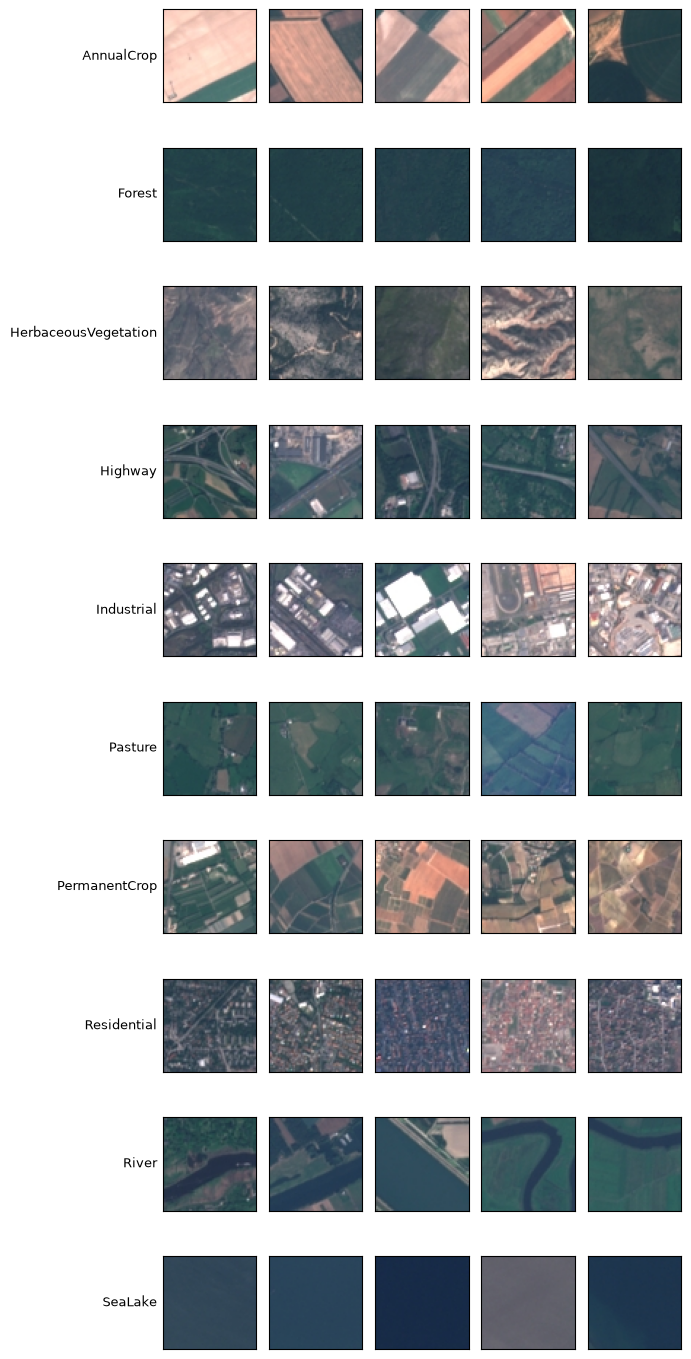

In [5]:
fig, axes = plt.subplots(len(class_names), 5, figsize=(7, 14))
for row, name in enumerate(class_names):
    samples = train[train["class_name"] == name].sample(5, random_state=42)
    for col, path in enumerate(samples["path"]):
        axes[row, col].imshow(Image.open(DATA_DIR / path))
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_samples.png", dpi=120)
plt.show()

**What I see:** Forest and SeaLake look smooth and dark, while Industrial and Residential are full of small bright detail, so texture should help a lot. One label does not mean one kind of land: the Highway images also contain fields and buildings, and one PermanentCrop image contains a large white building. AnnualCrop and PermanentCrop both show patchworks of fields, so these two look like a hard pair.

## 4. Per-class mean colour

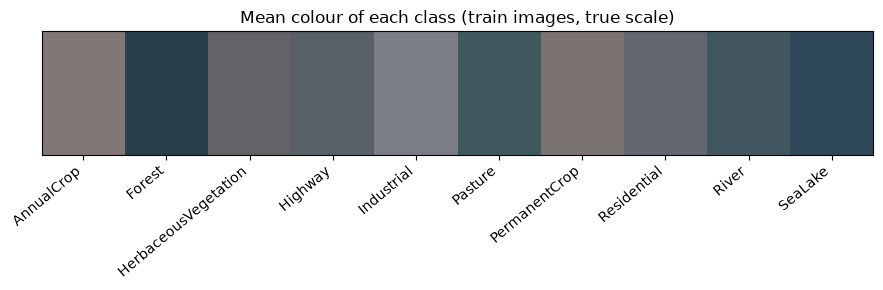

,R,G,B
AnnualCrop,129.6,120.0,117.2
Forest,39.4,64.5,75.9
HerbaceousVegetation,98.0,98.6,103.9
Highway,87.8,96.4,103.3
Industrial,123.4,125.5,134.4
Pasture,62.2,88.4,94.2
PermanentCrop,122.1,115.9,113.9
Residential,99.3,103.3,112.7
River,66.9,86.6,96.9
SeaLake,48.0,72.9,89.2


In [6]:
# Count how many pixels have each value 0..255, per class and per colour channel.
# We keep these counts for the mean colour here and the histograms in section 5.
hist = {name: np.zeros((3, 256), dtype=np.int64) for name in class_names}
for path, name in zip(train["path"], train["class_name"]):
    pixels = np.asarray(Image.open(DATA_DIR / path).convert("RGB"))
    for channel in range(3):
        hist[name][channel] += np.bincount(pixels[:, :, channel].ravel(), minlength=256)

values = np.arange(256)
mean_colour = pd.DataFrame(
    {name: (hist[name] * values).sum(axis=1) / hist[name].sum(axis=1) for name in class_names},
    index=["R", "G", "B"]).T

fig, ax = plt.subplots(figsize=(9, 3))
ax.imshow([mean_colour.to_numpy() / 255], aspect="auto")
ax.set_xticks(range(len(class_names)), class_names, rotation=40, ha="right")
ax.set_yticks([])
ax.set_title("Mean colour of each class (train images, true scale)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_mean_colour.png", dpi=120)
plt.show()
mean_colour.round(1)

**What I see:** Forest is the darkest class (39, 65, 76) and Industrial the brightest (123, 126, 134). Colour alone cannot separate every class: AnnualCrop (130, 120, 117) is close to PermanentCrop (122, 116, 114), and Pasture (62, 88, 94) is close to River (67, 87, 97). These are only averages, so the model will also need shape and texture. Rohan's confusion matrix will show whether these pairs really get mixed up.

## 5. Per-channel histograms

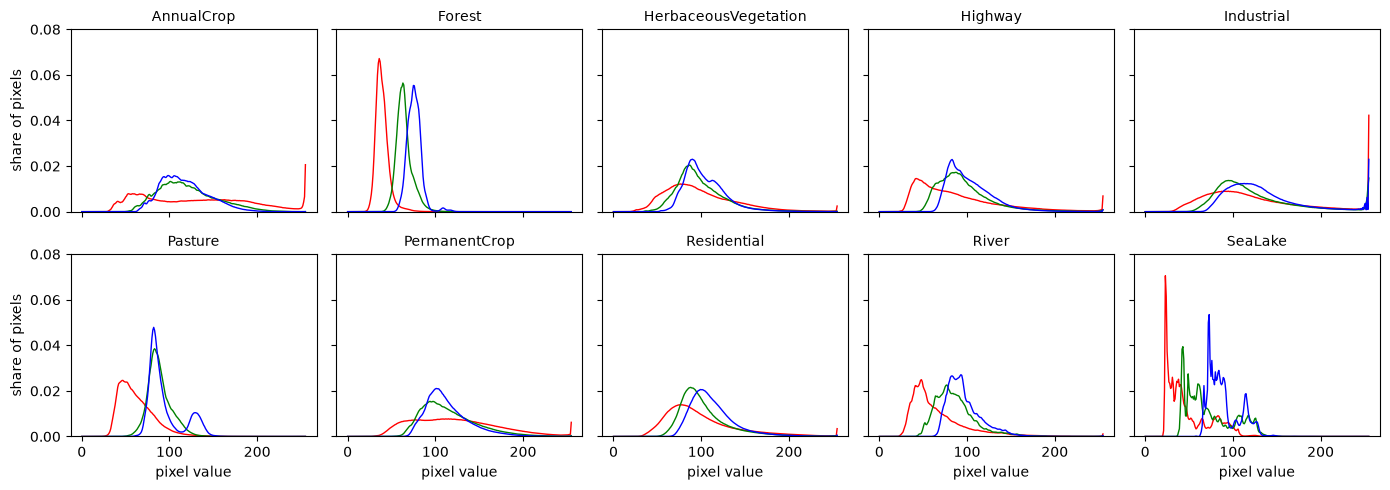

,p5,median,p95
AnnualCrop,60,116,202
Forest,33,63,84
HerbaceousVegetation,57,95,158
Highway,44,90,164
Industrial,66,117,243
Pasture,43,82,127
PermanentCrop,68,111,188
Residential,62,99,170
River,40,82,135
SeaLake,24,72,120


In [7]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), class_names):
    for channel, colour in enumerate(["red", "green", "blue"]):
        share = hist[name][channel] / hist[name][channel].sum()
        ax.plot(values, share, color=colour, linewidth=1)
    ax.set_title(name, fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("pixel value")
for ax in axes[:, 0]:
    ax.set_ylabel("share of pixels")
axes[0, 0].set_ylim(0, 0.08)  # SeaLake and Forest have tall peaks; the same scale keeps classes comparable
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_histograms.png", dpi=120)
plt.show()

# Numbers to back up what we read from the plot: the middle value and the spread of each class.
rows = {}
for name in class_names:
    grey = hist[name].sum(axis=0)
    cumulative = np.cumsum(grey) / grey.sum()
    rows[name] = {"p5": int(np.searchsorted(cumulative, 0.05)),
                  "median": int(np.searchsorted(cumulative, 0.50)),
                  "p95": int(np.searchsorted(cumulative, 0.95))}
pd.DataFrame(rows).T

**What I see:** Forest has narrow peaks, so its pixels are all similar and dark (5% to 95% of pixel values lie between 33 and 84). AnnualCrop and Industrial are much wider (60 to 202 and 66 to 243), and both have a spike at 255 where bright pixels are clipped to the maximum. SeaLake shows many thin peaks and the lowest values of all (5th percentile 24). Red sits lower than green and blue in most classes.

## 6. Augmentation and loader check

One training image passed through `augment()` eight times, then a check that the loader gives what the other parts expect.

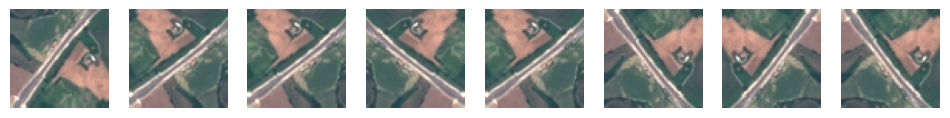

augment keeps the exact pixel values: True


In [8]:
image = Image.open(DATA_DIR / train[train["class_name"] == "Highway"]["path"].iloc[0]).convert("RGB")
transform = augment()

fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax in axes:
    ax.imshow(transform(image))
    ax.axis("off")
fig.savefig(FIGURES_DIR / "eda_augment.png", dpi=120, bbox_inches="tight")
plt.show()

# A rotation or flip only moves pixels, it must not change any value.
original = np.sort(np.asarray(image).ravel())
same_pixels = all(np.array_equal(original, np.sort(np.asarray(transform(image)).ravel())) for _ in range(50))
print("augment keeps the exact pixel values:", same_pixels)

In [9]:
images, labels = next(iter(get_loader("train", seed=0, augment=True)))
print("batch:", images.shape, labels.shape)
print("mean after normalising:", round(images.mean().item(), 3), " std:", round(images.std().item(), 3))

for fraction in [0.05, 0.1, 0.25, 0.5, 1.0]:
    subset = get_loader("train", fraction=fraction, seed=0).dataset.df
    print(f"fraction {fraction:<5} {len(subset):>6} images, smallest class {subset['label'].value_counts().min()}")

print("val:", len(get_loader("val").dataset), " test:", len(get_loader("test").dataset))

batch: torch.Size([64, 3, 64, 64]) torch.Size([64])
mean after normalising: -0.161  std: 0.833
fraction 0.05     945 images, smallest class 70
fraction 0.1     1890 images, smallest class 140
fraction 0.25    4725 images, smallest class 350
fraction 0.5     9450 images, smallest class 700
fraction 1.0    18900 images, smallest class 1400
val: 4050  test: 4050


**What I see:** the eight outputs are the same road in different directions and it is still clearly a highway, so the label stays correct. Every pixel value is kept exactly, because these rotations and flips only move pixels. The loader gives batches of 64 images of size 3x64x64, and at 5% the smallest class still has 70 images. After ImageNet normalisation this one batch has mean -0.161 and std 0.833, not 0 and 1, because the ImageNet numbers were not computed on EuroSAT. We keep them anyway since it is the team setting and all models get the same input.